# UNIVERSIDAD PERUANA UNIÓN
### FACULTAD DE INGENIERÍA Y ARQUITECTURA
**Escuela Profesional de Ingeniería de Sistemas**

---

| Ficha Técnica | Detalle del Proyecto |
| :--- | :--- |
| **Asignatura:** | Big Data & Machine Learning Distribuido |
| **Proyecto Sello:** | CitiBike Intelligent Mobility Platform |
| **Dimensión:** | **Dimensión 1:** Demanda Histórica y Predicción Temporal de Viajes |
| **Autor:** | Harry Jack Ascuña Mamani |
| **Stack:** | PySpark MLlib (Cluster Docker) · Parquet · Grafana |

---

### Formulación del Problema y Pregunta de Negocio
> **Pregunta de Investigación:**  
> *«¿Cómo varía históricamente la demanda de viajes según hora, día y tipo de usuario, y qué cantidad de viajes puede esperarse bajo estas condiciones?»*

#### Marco Analítico y Modelo Matemático
Se plantea la formulación supervisada de series temporales aplicando un desplazamiento analítico hacia adelante $\text{lead}()$:

$$Y_{t+1} = \text{lead}(\text{trip\_count}_t, 1)$$

Donde cada observación está caracterizada por el vector de características exógenas:

$$\mathbf{x}_t = \left[ \text{start\_hour}, \text{day\_of\_week}, \text{is\_weekend}, \text{trip\_count}_t, \mathbf{v}_{\text{user}}, \mathbf{v}_{\text{bike}} \right]^T$$

El objetivo es minimizar la función de costo del error cuadrático sobre el conjunto de test:

$$\mathcal{L}(\mathbf{w}) = \frac{1}{n} \sum_{i=1}^{n} \left( y_{i, t+1} - \hat{y}_{i, t+1} \right)^2 + \lambda \|\mathbf{w}\|_2^2$$

---

## Bloque 1: Inicialización de Spark


In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import *


In [2]:
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml import Pipeline, PipelineModel
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd, os
sns.set_theme(style='whitegrid')


In [3]:
spark = SparkSession.builder.appName('u2-demanda-offline').master('local[*]').config('spark.sql.shuffle.partitions', '8').getOrCreate()
spark.sparkContext.setLogLevel('ERROR')
spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/30 20:45:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/30 20:45:13 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


## Bloque 2: Esquema Contractual Bronze y Limpieza Silver


In [4]:
schema = StructType([
    StructField('ride_id', StringType(), True),
    StructField('rideable_type', StringType(), True),
    StructField('started_at', TimestampType(), True),
    StructField('ended_at', TimestampType(), True),
    StructField('start_station_name', StringType(), True),
    StructField('start_station_id', StringType(), True),
    StructField('end_station_name', StringType(), True),
    StructField('end_station_id', StringType(), True),
    StructField('start_lat', DoubleType(), True),
    StructField('start_lng', DoubleType(), True),
    StructField('end_lat', DoubleType(), True),
    StructField('end_lng', DoubleType(), True),
    StructField('member_casual', StringType(), True)
])


In [5]:
df_raw = spark.read.schema(schema).option('header', True).csv('data/*.csv')


In [6]:
df_silver = (
    df_raw
    .filter(F.col('started_at').isNotNull() & F.col('ended_at').isNotNull())
    .withColumn('duration_minutes', (F.col('ended_at').cast('long') - F.col('started_at').cast('long')) / 60.0)
    .filter((F.col('duration_minutes') >= 1.0) & (F.col('duration_minutes') <= 180.0))
    .dropDuplicates(['ride_id'])
)


In [7]:
print('Registros Silver:', df_silver.count())


[Stage 2:>                                                          (0 + 8) / 8]

Registros Silver: 4987477


## Bloque 3: Extracción de Features Temporales y Demanda Agregada


In [8]:
df_feat = (
    df_silver
    .withColumn('trip_date', F.to_date('started_at'))
    .withColumn('start_hour', F.hour('started_at'))
    .withColumn('day_of_week', F.dayofweek('started_at'))
    .withColumn('is_weekend', F.when(F.col('day_of_week').isin(1, 7), 1).otherwise(0))
)


In [9]:
df_demanda = (
    df_feat.groupBy('trip_date', 'start_hour', 'day_of_week', 'is_weekend', 'member_casual', 'rideable_type')
    .agg(F.count('*').alias('trip_count'))
)


In [10]:
df_demanda.orderBy('trip_date', 'start_hour').show(5)


[Stage 8:>                                                          (0 + 8) / 8]

+----------+----------+-----------+----------+-------------+-------------+----------+
| trip_date|start_hour|day_of_week|is_weekend|member_casual|rideable_type|trip_count|
+----------+----------+-----------+----------+-------------+-------------+----------+
|2026-06-30|        21|          3|         0|       member|electric_bike|         2|
|2026-06-30|        22|          3|         0|       casual|electric_bike|        15|
|2026-06-30|        22|          3|         0|       member|electric_bike|         7|
|2026-06-30|        22|          3|         0|       member| classic_bike|         1|
|2026-06-30|        23|          3|         0|       member|electric_bike|       414|
+----------+----------+-----------+----------+-------------+-------------+----------+
only showing top 5 rows


### Gráfico 1: Demanda Horaria Promedio


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

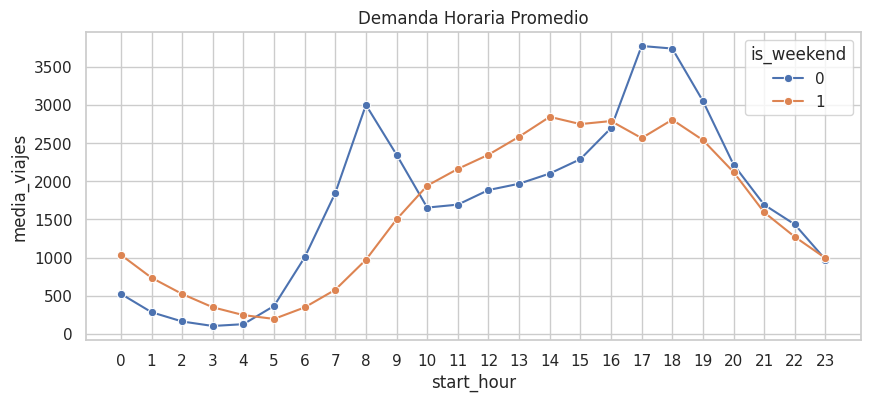

In [11]:
pd_curva = df_demanda.groupBy('start_hour', 'is_weekend').agg(F.avg('trip_count').alias('media_viajes')).toPandas()
plt.figure(figsize=(10, 4))
sns.lineplot(data=pd_curva, x='start_hour', y='media_viajes', hue='is_weekend', marker='o')
plt.title('Demanda Horaria Promedio')
plt.xticks(range(0, 24))
plt.show()


## Bloque 4: Formulación Supervisada con lead() y Partición Cronológica


In [12]:
w = Window.orderBy('trip_date', 'start_hour')
ds_ml = df_demanda.withColumn('label', F.lead('trip_count', 1).over(w)).na.drop()


In [13]:
num = ds_ml.withColumn('rn', F.row_number().over(w))
corte = int(num.count() * 0.8)
train = num.filter(F.col('rn') <= corte).drop('rn')
test = num.filter(F.col('rn') > corte).drop('rn')
print(f'Train: {train.count()} | Test: {test.count()}')


[Stage 44:>                                                         (0 + 8) / 8]

Train: 2385 | Test: 597


## Bloque 5: Evaluación y Comparación contra Persistencia


In [14]:
eval_rmse = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='rmse')
eval_mae = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='mae')
eval_r2 = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='r2')

def ev(df, nom):
    return {'Modelo': nom, 'RMSE': eval_rmse.evaluate(df), 'MAE': eval_mae.evaluate(df), 'R2': eval_r2.evaluate(df)}


In [15]:
res_p = ev(test.withColumn('prediction', F.col('trip_count').cast('double')), 'Persistencia')


In [16]:
u_idx = StringIndexer(inputCol='member_casual', outputCol='u_idx', handleInvalid='keep')
b_idx = StringIndexer(inputCol='rideable_type', outputCol='b_idx', handleInvalid='keep')
enc = OneHotEncoder(inputCols=['u_idx', 'b_idx'], outputCols=['u_v', 'b_v'])
asm = VectorAssembler(inputCols=['start_hour', 'day_of_week', 'is_weekend', 'trip_count', 'u_v', 'b_v'], outputCol='features')
prep = Pipeline(stages=[u_idx, b_idx, enc, asm]).fit(train)
tr_p = prep.transform(train)
te_p = prep.transform(test)


In [17]:
lr = LinearRegression(featuresCol='features', labelCol='label').fit(tr_p)
res_lr = ev(lr.transform(te_p), 'LinearRegression')


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory
                                                                                

In [18]:
rf = RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=30, seed=42).fit(tr_p)
res_rf = ev(rf.transform(te_p), 'RandomForest')


In [19]:
tabla = pd.DataFrame([res_p, res_lr, res_rf])
tabla['Mejora_%'] = 100 * (res_p['RMSE'] - tabla['RMSE']) / res_p['RMSE']
print(tabla)


             Modelo         RMSE          MAE        R2   Mejora_%
0      Persistencia  2751.140351  1893.108878 -0.699710   0.000000
1  LinearRegression  1931.457404  1344.129788  0.162240  29.794298
2      RandomForest  1791.834604  1203.786433  0.278984  34.869386


### Gráfico 2: Comparación de Métricas


/tmp/ipykernel_149060/1988609763.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tabla, x='Modelo', y='RMSE', palette='Blues_r')


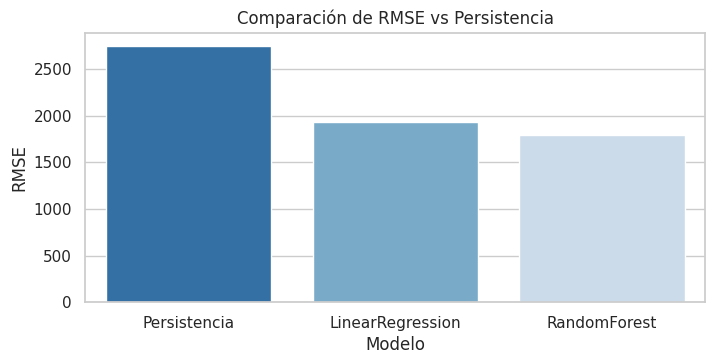

In [20]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=tabla, x='Modelo', y='RMSE', palette='Blues_r')
plt.title('Comparación de RMSE vs Persistencia')
plt.show()


## Bloque 6: Exportación de PipelineModel


In [21]:
os.makedirs('./artifacts/models', exist_ok=True)
p_final = Pipeline(stages=[u_idx, b_idx, enc, asm, lr]).fit(train)
p_final.write().overwrite().save('./artifacts/models/modelo_demanda_lr')
print('Modelo guardado correctamente.')


Modelo guardado correctamente.
